### imports

In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d


## Load all sessions

In [ ]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


## Scale experimental forces to use them as inputs to the model 

43264
43520
14592
43520
43520
14080
43264
28672
43520
32512
43520
19456
43776
43520
37632
27392
36864
24576
43776
43776
43520
25344
16128
15616
20736
12544
12032
15616
16128
16128
34048
35072
11008
8960
6400
11776
12288
35840
17920
10496
14592
17664
17920
17408
15104
15360
22272
22272
11264
19968
11008
31232
43776
19968
32000
18688
18688
22016
17408
20480
27648
13824
17920
10496
22272
20992
17152
22016
26368
10496
21248
17920
28928
18176
29952
21760
19712
12288
25600
35584
43264
16896
10752
43776
38656
22784
43520
15872
43776
44544
23040
24320
12288
12032
15616
25344
25344
13824
16640
11776
43520
39168
43776
17920
44032
12544
44032
43264
43776
44800
12800
16128
14592
17920
10752
23040
11520
12544
11264
14080
21248
11776
11776
18432
10240
11520
17152
11008
16384
16128
Global maximum force (before scaling): 0.2424
Scaling factor to apply: 4.5371
Saved scaled force for Day01 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day01

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6352/4162411560.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10")


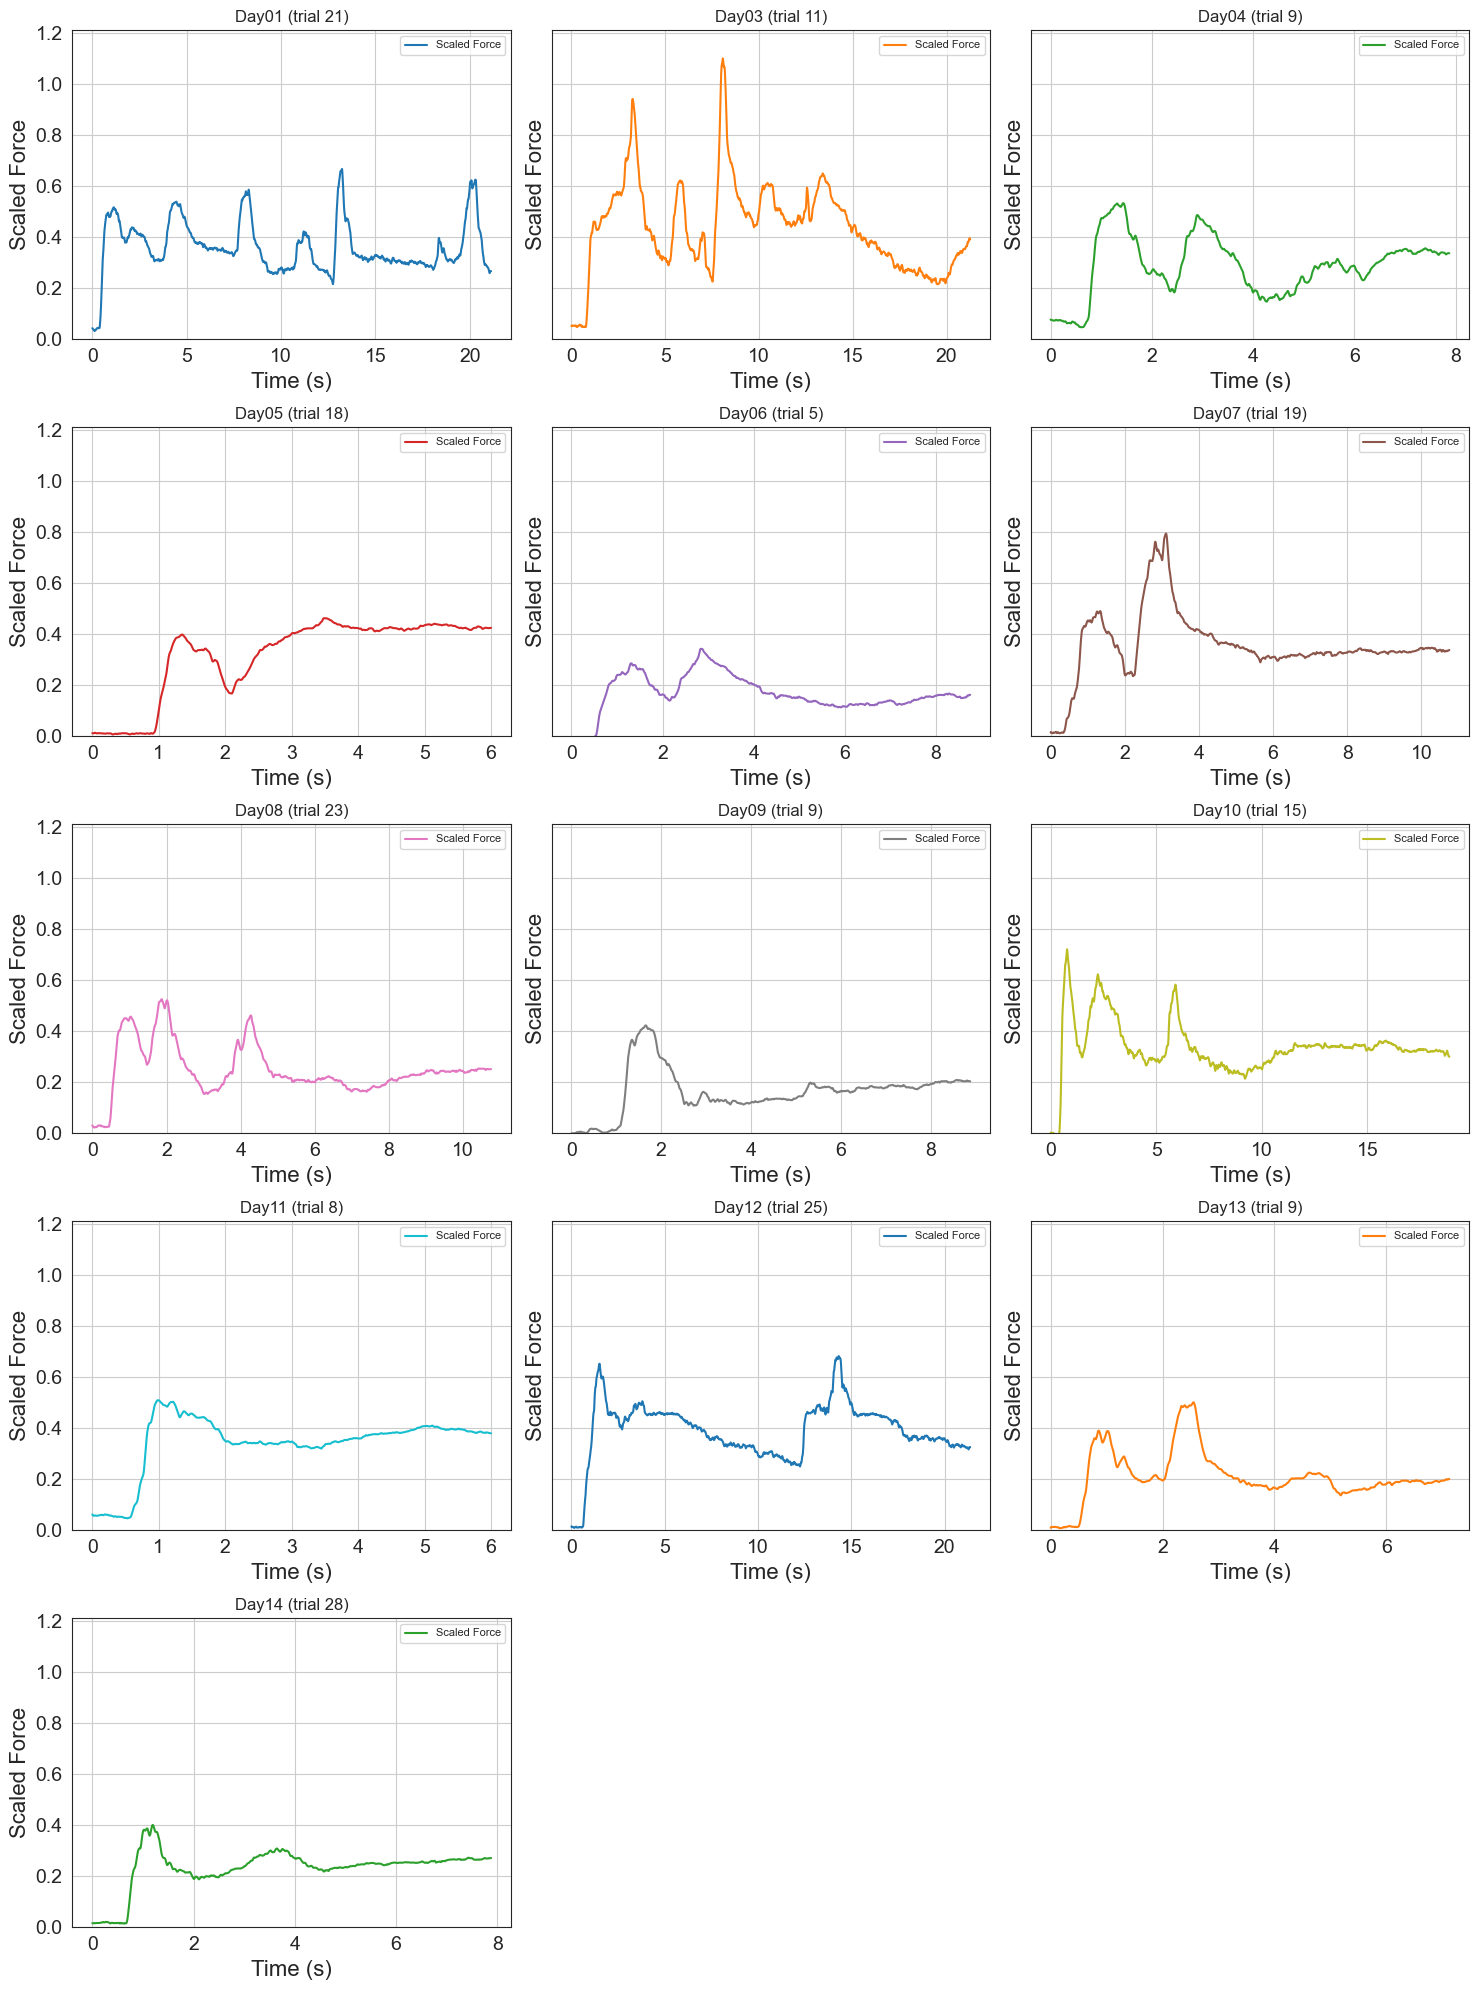

In [ ]:
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_representative_trial(directory_path, save_dir, file_prefix="represetative_trial", target_max=0.4, fsamp=2048, plot=True,trial_numbers_by_day=None):

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # if list is given, align it to session_days
    day_to_trialnum = None
    if isinstance(trial_numbers_by_day, list):
        if len(trial_numbers_by_day) != len(session_days):
            raise ValueError(
                f"Length of trial_numbers_by_day list ({len(trial_numbers_by_day)}) "
                f"must match number of days ({len(session_days)})."
            )
        day_to_trialnum = {day: tn for day, tn in zip(session_days, trial_numbers_by_day)}
    elif isinstance(trial_numbers_by_day, dict):
        day_to_trialnum = trial_numbers_by_day
    else:
        raise ValueError("Provide trial_numbers_by_day (list or dict) to select a specific trial per day.")

    average_force_by_day = {}
    time_by_day = {}

    for day in session_days:
        session_files = files_by_day[day]

        # Load all trial forces for the day
        raw_forces, trial_lengths, trial_nums = [], [], []
        for file_name in session_files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
            force = np.array(data['Force'].tolist())[0]
            raw_forces.append(force)
            trial_lengths.append(len(force))
            trial_nums.append(extract_trial(file_name))

        # Use the specific trial only (no averaging)
        selected_trialnum = int(day_to_trialnum[day])
        candidates = [i for i, tn in enumerate(trial_nums) if tn == selected_trialnum]
        if not candidates:
            raise ValueError(f"Day {day}: trial number {selected_trialnum} not found in filenames {trial_nums}.")
        idx = candidates[0]
        selected_force = raw_forces[idx]

        min_length = len(selected_force)
        new_time = np.linspace(0, 1, min_length)
        old_time = np.linspace(0, 1, len(selected_force))
        interp_func = interp1d(old_time, selected_force, kind='linear')
        downsampled = interp_func(new_time)

        mean_force = downsampled  # using the selected trial only
        std_force = np.zeros_like(mean_force)  # no variability when not averaging
        time_axis = np.linspace(0, len(selected_force) / fsamp, min_length)

        average_force_by_day[day] = {
            'mean': mean_force,
            'std': std_force,
            'selected_trialnum': selected_trialnum
        }
        time_by_day[day] = time_axis

    all_max = max(np.max(average_force_by_day[day]['mean']) for day in session_days)
    scaling_factor = target_max / all_max if all_max > 0 else 1.0
    print(f"Global maximum force (before scaling): {all_max:.4f}")
    print(f"Scaling factor to apply: {scaling_factor:.4f}")

    os.makedirs(save_dir, exist_ok=True)

    for day in session_days:
        mean_force = average_force_by_day[day]['mean']
        scaled_force = mean_force * scaling_factor

        sel_trial = average_force_by_day[day]['selected_trialnum']
        suffix = f"_trial{sel_trial:02d}"

        filename = f"{file_prefix}_{day}.npy"
        save_path = os.path.join(save_dir, filename)
        np.save(save_path, scaled_force)
        print(f"Saved scaled force for {day} to {save_path}")

    if plot:
        cols = 3
        rows = int(np.ceil(len(session_days) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=True)
        axes = axes.flatten()
        cmap = cm.get_cmap("tab10")

        for i, day in enumerate(session_days):
            mean = average_force_by_day[day]['mean'] * scaling_factor
            t    = time_by_day[day]
            color = cmap(i % 10)
            sel_trial = average_force_by_day[day]['selected_trialnum']

            ax = axes[i]
            ax.plot(t, mean, color=color, label='Scaled Force')
            title_tag = f"{day} (trial {sel_trial})"
            ax.set_title(title_tag, fontsize=12)
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("Scaled Force")
            ax.set_ylim([0, target_max * 1.1])
            ax.grid(True)
            ax.legend(fontsize=8)

        # remove unused axes
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show()

s1_trials = [21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28]

compute_representative_trial(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/",
    file_prefix="force_S111111",
    target_max=1.1,
    trial_numbers_by_day=[21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28],
    plot=True
)


[16.74115338 17.42241276 17.37445613 17.45857867 17.20779141 17.26262666
 17.46840274 16.8462378  17.38952037 17.01004472 16.67163719 16.65474709
 16.50561044 16.80196153 16.79659955 16.8905313  16.83847788 16.8519648
 16.79691601 16.88259258 17.09326359 16.59730722 16.68219921 17.67221228
 16.82225624 17.22248317 16.4369891  17.52269262 17.33560557 16.71109891
 16.73320808 16.02705053 16.26361712 17.4434985  16.60702345 17.19459445
 16.59105258 16.10779    15.90482552 16.36436684 16.60699545 17.02864776
 17.27445338 16.03978649 15.48450325 15.63629967 16.8789583  15.66427542
 16.97066325 15.84359826 17.30116526 17.30706059 16.73775318 16.86543199
 17.4204519  17.71886717 16.96203584 15.07295457 17.24032375 16.08923904
 15.17688414 14.5640894  14.89118831 14.72150179 17.4025263  14.14632824
 18.1871072  14.11056566 17.88628245 13.86471504 16.66192945 13.84120676
 13.9282301  14.95431579 16.30758156 14.58235975 13.74734173 13.18385028
 15.25205118 14.47392471 13.46891712 16.40379785 13.

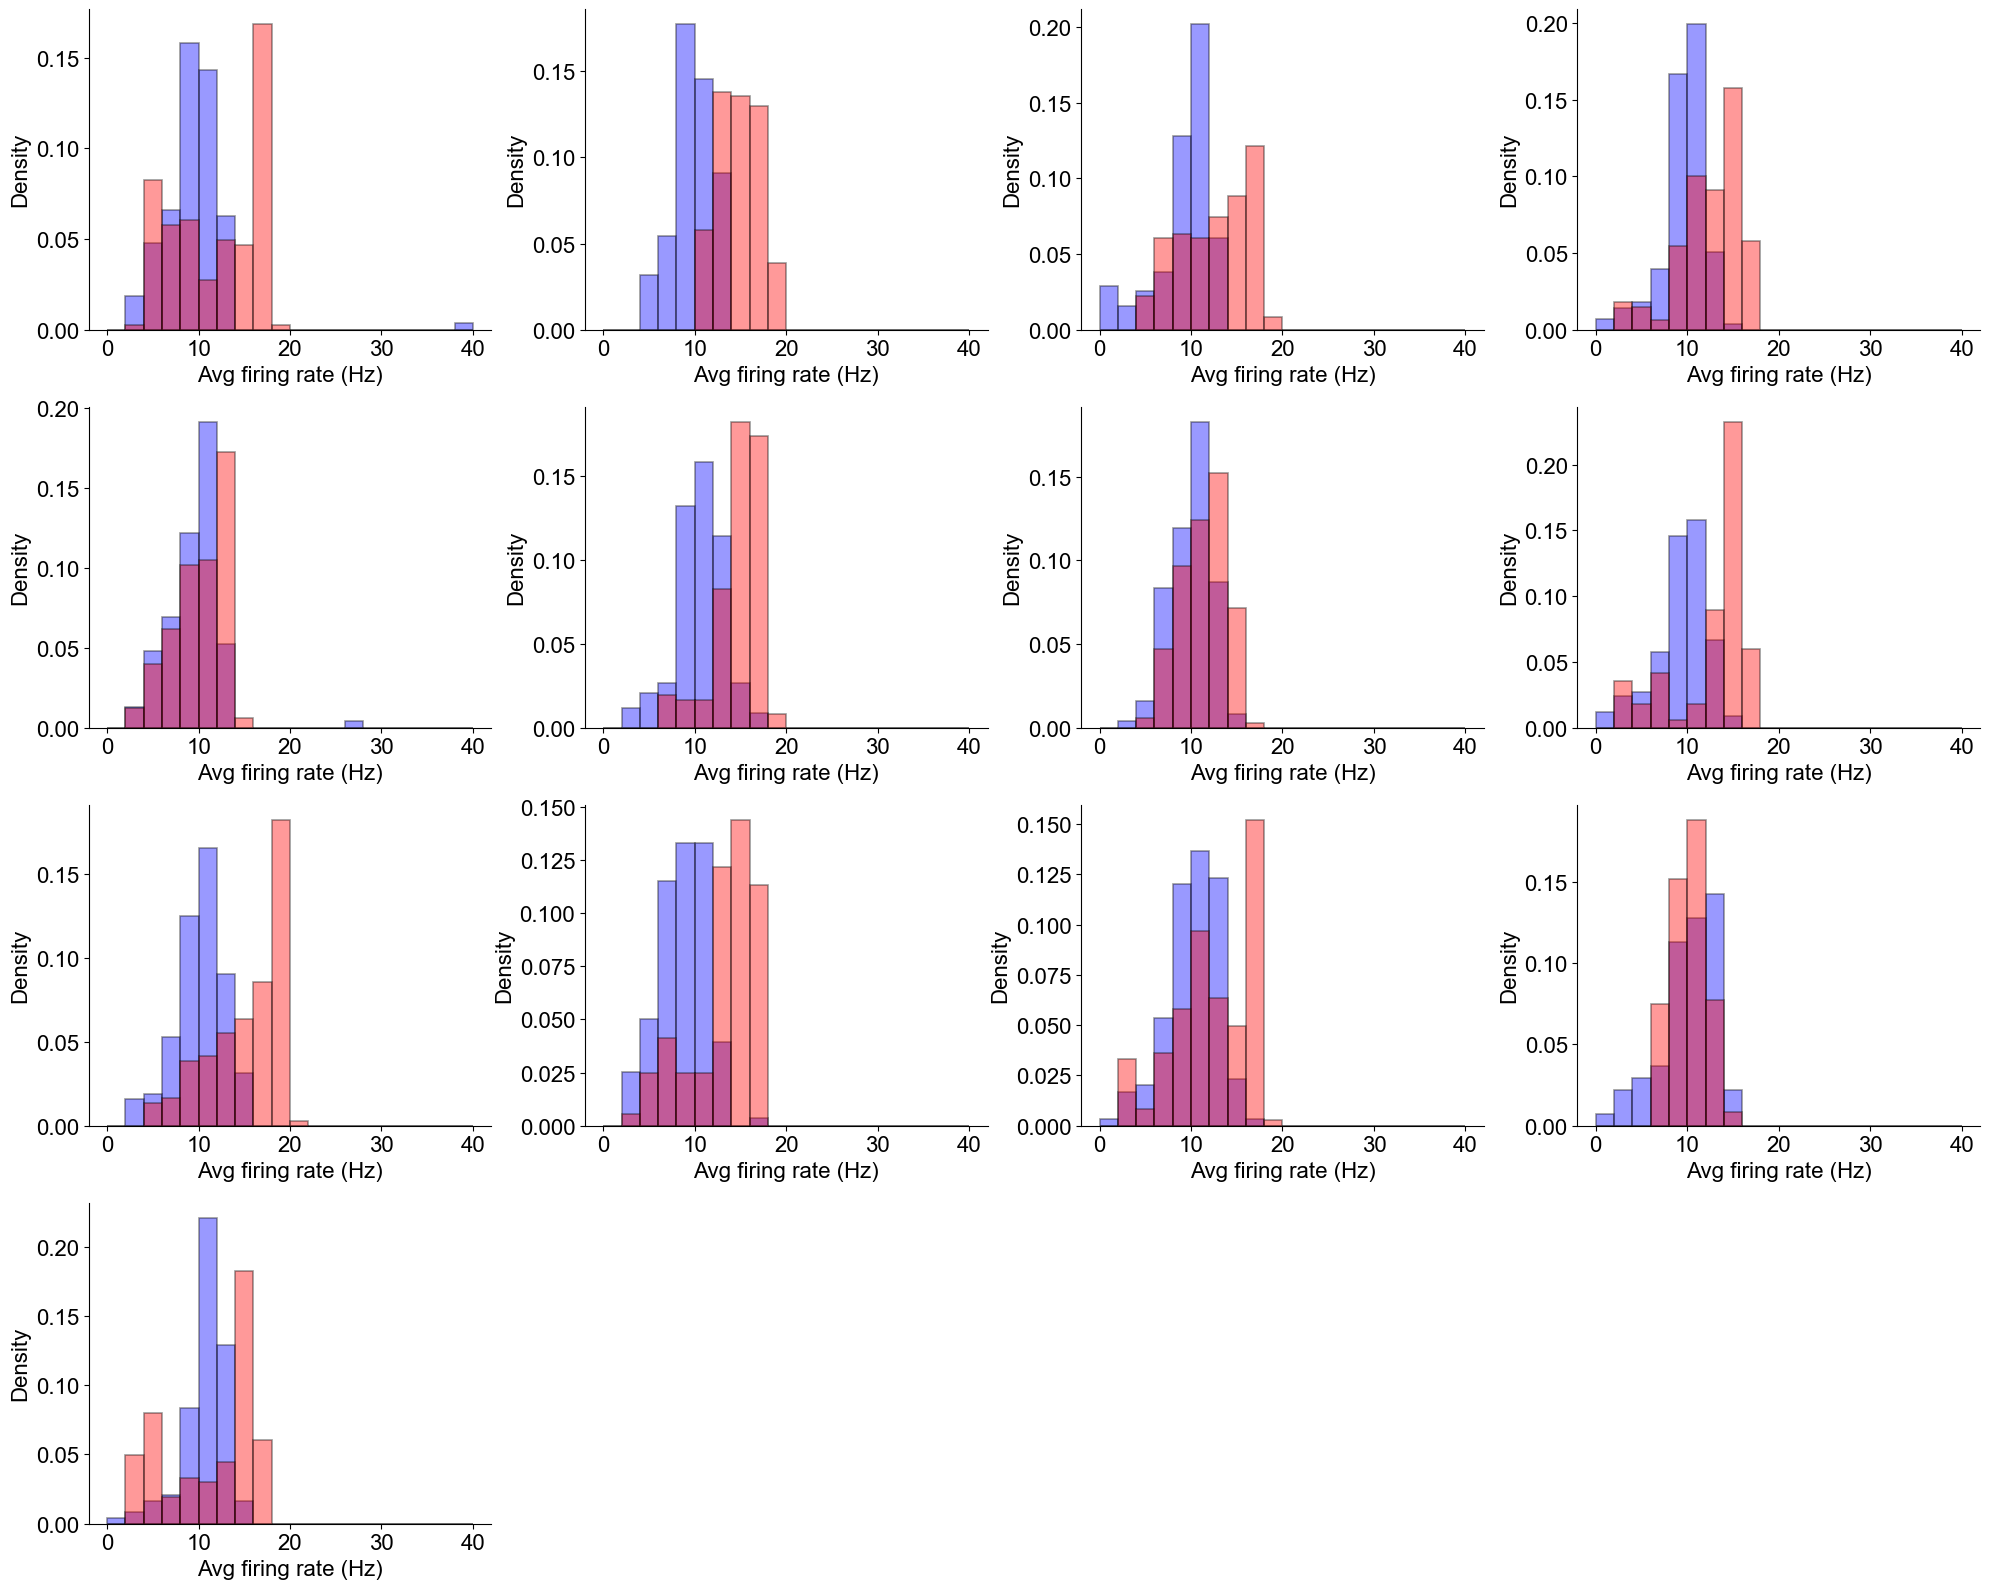

In [72]:
import os
import re
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt



def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_avg_firing_rate(spike_times, sampling_rate):
    if len(spike_times) < 2:
        return None
    ISIs = np.diff(spike_times) / sampling_rate
    return 1 / np.mean(ISIs)

def load_simulated_rates(jld2_file_paths):
    sim_rates_by_day = {}
    for path in jld2_file_paths:
        day_match = re.search(r'force(\d+)_firing_rates_rep_\.jld2', path)
        if not day_match:
            continue
        day = int(day_match.group(1))

        with h5py.File(path, 'r') as f:
            if 'avg_rates_per_neuron' in f:
                rates = f['avg_rates_per_neuron'][:]
                sim_rates_by_day[day] = rates
                print(sim_rates_by_day[day])
            else:
                print(f"'avg_rates_per_neuron' not found in {path}")
    return sim_rates_by_day

def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
    sim_data = load_simulated_rates(jld2_file_paths)
    pkl_files = sorted(
        [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
        key=lambda x: (extract_day(x), extract_trial(x))
    )
    day_files = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            day_files.setdefault(day, []).append(file)

    n_days = len(day_files)
    n_cols = 4
    n_rows = int(np.ceil(n_days / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, (day, files) in enumerate(sorted(day_files.items())):
        all_firing_rates = []
        for file in files:
            with open(os.path.join(folder_path, file), 'rb') as f:
                data = pickle.load(f)
            MU_array = np.array(data['MU'])

            for neuron_idx in range(MU_array.shape[0]):
                spike_times = np.where(MU_array[neuron_idx] == 1)[0]
                fr = compute_avg_firing_rate(spike_times, Fsamp)
                if fr is not None and fr <= 80:
                    all_firing_rates.append(fr)

        ax = axes[i]
        bin_edges = np.linspace(0, 40, 21)

        ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
                label='Experimental', density=True, edgecolor='black', linewidth=1.2)

        if day in sim_data:
            ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
                    label='Simulated', density=True, edgecolor='black', linewidth=1.2)

        # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
        ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
        ax.set_ylabel('Density', fontsize=16)

        # Remove legend
        # ax.legend()

        # Remove top and right spines
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

        # Make ticks bigger
        ax.tick_params(axis='both', which='major', labelsize=16)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    return fig



folder_path = "/Users/nmt121/Desktop/DATA/S1"
Fsamp = 2048

jld2_file_paths = [
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
    
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_rep_.jld2',


    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force13_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force13_firing_rates.jld2', 
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force14_firing_rates.jld2',
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force2_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force6_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates7.jld2',




]

fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S1.pdf', dpi=300, bbox_inches='tight')
plt.show()



## Get rasters for each of the trials



In [81]:
from functions_experimental_data_Bräckleinexp.create_rasters import *
fig = create_raster('/Users/nmt121/Desktop/DATA/S7/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
plt.show(fig)
# fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

# Behavioral analysis

## Plot force trajectories for every day and every trial

In [ ]:
# from functions_experimental_data_Bräckleinexp.force_trajectories import *
# fsamp = 2048  
# highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
# fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S1/',fsamp=2048,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# plt.show(fig)
# # # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

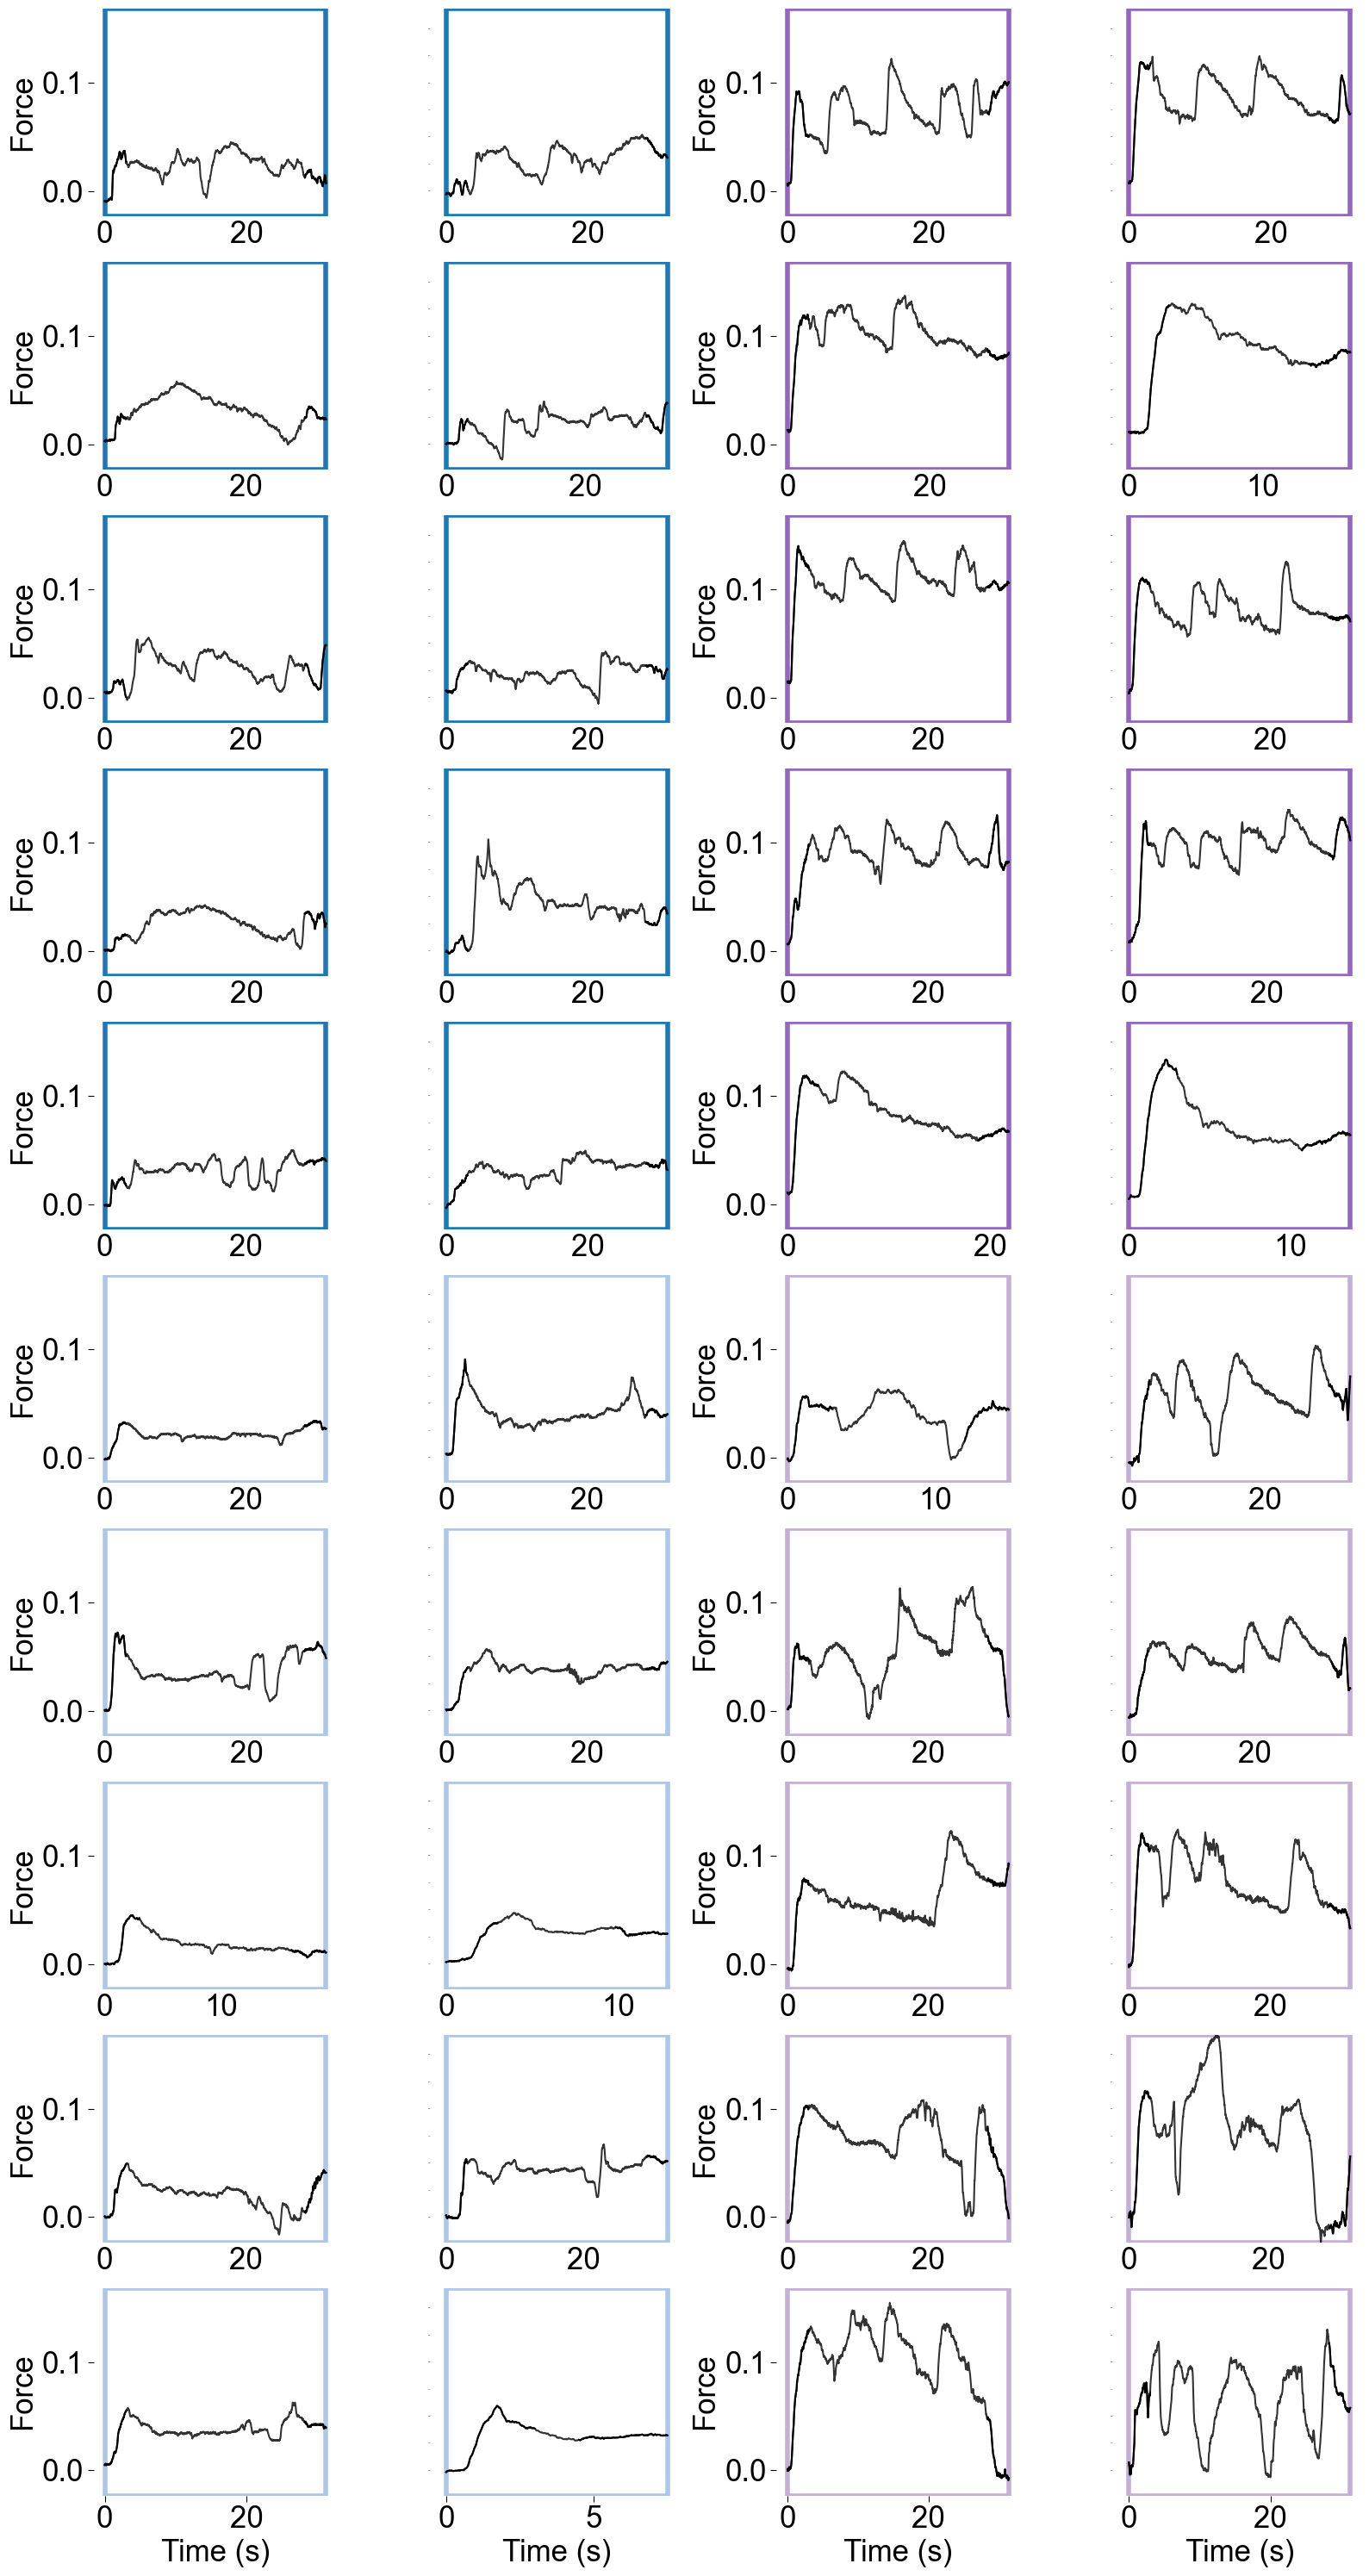

In [82]:
from functions_experimental_data_Bräckleinexp.force_trajectories import *
plot_force_trials(directory_path="/Users/nmt121/Desktop/DATA/S7",output_path="/Users/nmt121/Desktop/Figures/S7force.pdf")

## Measure smoothness of the force signal 

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_11716/2478925649.py:63: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_11716/2478925649.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


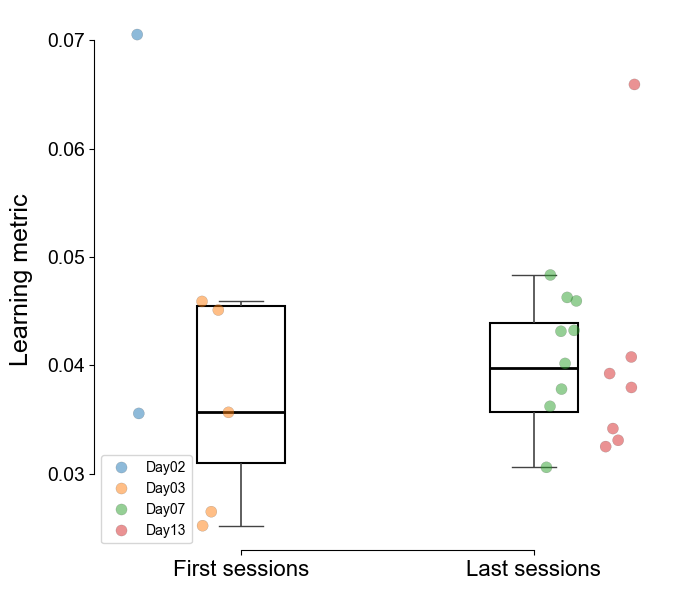

In [ ]:
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

def compute_smoothness(force_signal, fsamp, high_freq_threshold=5.0):
    
    freqs = np.fft.rfftfreq(len(force_signal), d=1/fsamp)
    amp_spectrum = np.abs(np.fft.rfft(force_signal)) / len(force_signal)
    smoothness= np.sum(amp_spectrum[freqs > high_freq_threshold])
    return smoothness


def compute_signal_smoothness(directory_path, fsamp):
    import matplotlib.patches as patches
    from matplotlib import rcParams

    # Set font globally
    rcParams['font.family'] = 'Arial'
    rcParams['axes.labelsize'] = 16
    rcParams['xtick.labelsize'] = 14
    rcParams['ytick.labelsize'] = 14

    # 1. Load and group files
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    if len(session_days) < 4:
        raise ValueError("Need at least 4 days to compute first vs last two.")

    first_days = session_days[:2]
    last_days = session_days[-2:]

    records = []
    for group_label, group_days in zip(["First sessions", "Last sessions"], [first_days, last_days]):
        for day in group_days:
            files_by_day[day].sort(key=extract_trial)
            for file_name in files_by_day[day]:
                file_path = os.path.join(directory_path, file_name)
                with open(file_path, 'rb') as f:
                    data = pickle.load(f)

                force_signal = np.array(data['Force'].tolist())[0]
                if (len(force_signal)/2048)<17:
                    smoothness = compute_smoothness(force_signal, fsamp)
                    records.append({"Group": group_label,"Day": day,"Smoothness": smoothness  })

    df = pd.DataFrame(records)
    

    plt.figure(figsize=(7, 6))
    ax = plt.gca()

    # Transparent colored dots by session
    sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)

    # Standard boxplot (Q1–Q3 + median)
    sns.boxplot(data=df, x="Group", y="Smoothness",showcaps=True, showfliers=False,whiskerprops={'linewidth': 1.2},boxprops={'facecolor': 'none', 'edgecolor': 'black', 'linewidth': 1.5},medianprops={'color': 'black', 'linewidth': 2}, width=0.3,ax=ax)

    group_stats = df.groupby("Group")["Smoothness"].agg(["mean", "std", "count"])
    for i, group in enumerate(["First sessions", "Last sessions"]):
        mean_val = group_stats.loc[group, "mean"]
        std_val = group_stats.loc[group, "std"]
        n = group_stats.loc[group, "count"]
        sem = std_val / np.sqrt(n)


    ax.set_ylabel("Learning metric", fontsize=18, labelpad=10)
    ax.set_xlabel("")
    ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)
    sns.despine(trim=True)


    plt.tight_layout()
    return plt.gcf()

fig = compute_signal_smoothness('/Users/nmt121/Desktop/DATA/S2/', fsamp=2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/learningmetric7_amplitudefft.pdf", dpi=300, bbox_inches='tight')

## Success rate

In [92]:
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

def trial_success_rate_per_day(directory_path, fsamp=2048, success_thresh=17.0):

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    
    # group files by day
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day:
            files_by_day.setdefault(day, []).append(f)
    
    results = {}
    for day, files in sorted(files_by_day.items()):
        n_total, n_success = 0, 0
        for file_name in files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
            force_signal = np.array(data['Force'].tolist())[0]
            duration_sec = len(force_signal) / fsamp

            n_total += 1
            if duration_sec < success_thresh:
                n_success += 1

        success_rate = 100.0 * n_success / n_total if n_total > 0 else np.nan
        results[day] = {"success_rate": success_rate,"n_success": n_success,"n_total": n_total}
    
    return results


results = trial_success_rate_per_day('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)

for day, stats in results.items():
    print(f"{day}: {stats['success_rate']:.1f}% ({stats['n_success']}/{stats['n_total']})")



Day01: 40.0% (4/10)
Day03: 30.0% (3/10)
Day04: 90.9% (10/11)
Day05: 80.0% (8/10)
Day06: 100.0% (10/10)
Day07: 90.0% (9/10)
Day08: 100.0% (9/9)
Day09: 90.0% (9/10)
Day10: 40.0% (4/10)
Day11: 100.0% (10/10)
Day12: 20.0% (2/10)
Day13: 100.0% (10/10)
Day14: 100.0% (10/10)


In [310]:
import numpy as np
from scipy import stats

# Data
day1 = [40,20,10,0,0,0]
day2 = [50,60,100,30,70,20]
day13 = [10,90,100,30,80,52.9]
day14 = [100,70,100,66.7,70,10]

# Grouping
first_sessions = np.array(day1 + day2)
last_sessions  = np.array(day13 + day14)

# Descriptive stats
print("First sessions mean ± std: %.2f ± %.2f" % (np.mean(first_sessions), np.std(first_sessions)))
print("Last sessions mean ± std:  %.2f ± %.2f" % (np.mean(last_sessions), np.std(last_sessions)))

# Independent samples t-test (Welch's)
t_stat, p_val = stats.ttest_ind(first_sessions, last_sessions, equal_var=False)
print("Welch t-test: t = %.3f, p = %.4f" % (t_stat, p_val))

# Mann-Whitney U test (nonparametric alternative)
u_stat, p_u = stats.mannwhitneyu(first_sessions, last_sessions, alternative="two-sided")
print("Mann–Whitney U: U = %.3f, p = %.4f" % (u_stat, p_u))


First sessions mean ± std: 33.33 ± 30.37
Last sessions mean ± std:  64.97 ± 31.62
Welch t-test: t = -2.393, p = 0.0257
Mann–Whitney U: U = 34.000, p = 0.0295


## Take most representative trial

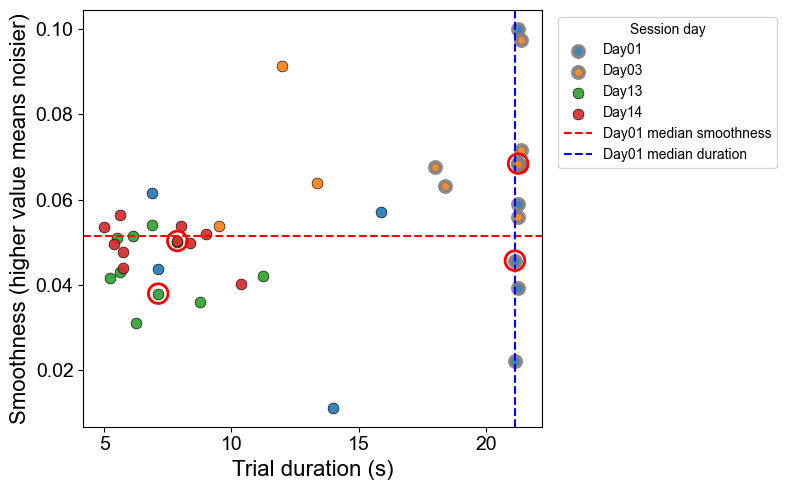

       Day  Trial                      File  TrialDur_s  Smoothness
6    Day01     21  E3_MB01_Day01High_21.pkl      21.125    0.045720
13   Day03     11  E3_MB01_Day03High_11.pkl      21.250    0.068481
22   Day04      9   E3_MB01_Day04High_9.pkl       7.875    0.051828
36   Day05     18  E3_MB01_Day05High_18.pkl       6.000    0.080721
42   Day06      5   E3_MB01_Day06High_5.pkl       8.750    0.034478
57   Day07     19  E3_MB01_Day07High_19.pkl      10.750    0.063988
67   Day08     23  E3_MB01_Day08High_23.pkl      10.750    0.044008
73   Day09      9   E3_MB01_Day09High_9.pkl       8.875    0.040275
84   Day10     15  E3_MB01_Day10High_15.pkl      18.875    0.059173
92   Day11      8   E3_MB01_Day11High_8.pkl       6.000    0.062577
108  Day12     25  E3_MB01_Day12High_25.pkl      21.375    0.062187
112  Day13      9   E3_MB01_Day13High_9.pkl       7.125    0.037995
129  Day14     28  E3_MB01_Day14High_28.pkl       7.875    0.050339


In [46]:
def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def load_force(file_path):
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    try:
        x = np.array(data['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(data['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(data['Force'].tolist())[0].squeeze()
    return np.asarray(x, float)

def duration_vs_smoothness_scatter_with_median(directory_path, fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True, save_path=None):
    # Collect files by day (ALL days)
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day is not None:
            files_by_day.setdefault(day, []).append(f)
    for day in files_by_day:
        files_by_day[day].sort(key=extract_trial)

    days_all = sorted(files_by_day.keys())
    # Days to plot (first 2 + last 2), but compute for all
    if keep_first_last and len(days_all) >= 4:
        days_to_plot = days_all[:2] + days_all[-2:]
    else:
        days_to_plot = days_all

    # Build records for ALL days
    records = []
    for day in days_all:
        for fname in files_by_day[day]:
            fpath = os.path.join(directory_path, fname)
            try:
                x = load_force(fpath)
            except Exception:
                continue
            
            trial_dur = len(x) / fsamp
            smoothness = compute_smoothness(x, fsamp, high_freq_threshold)
            records.append({
                "Day": day,
                "Trial": extract_trial(fname),
                "TrialDur_s": trial_dur,
                "Smoothness": smoothness,
                "File": fname
            })
    if not records:
        print("No valid trials found.")
        return None, None

    df_all = pd.DataFrame(records)

    # Picks (per-day median) for ALL days
    picks = []
    for day, g in df_all.groupby("Day", sort=True):
        mx = g["TrialDur_s"].median()
        my = g["Smoothness"].median()
        iqr_x = np.percentile(g["TrialDur_s"], 75) - np.percentile(g["TrialDur_s"], 25)
        iqr_y = np.percentile(g["Smoothness"], 75) - np.percentile(g["Smoothness"], 25)
        sx = iqr_x if iqr_x > 0 else (g["TrialDur_s"].std() or 1.0)
        sy = iqr_y if iqr_y > 0 else (g["Smoothness"].std() or 1.0)
        dist = np.sqrt(((g["TrialDur_s"]-mx)/sx)**2 + ((g["Smoothness"]-my)/sy)**2)
        pick = g.loc[dist.idxmin(), ["Day","Trial","File","TrialDur_s","Smoothness"]]
        picks.append(pick)
    selected_all = pd.DataFrame(picks)

    # === Plot ONLY the 4 days (or all, if <4) ===
    df_plot = df_all[df_all["Day"].isin(days_to_plot)].copy()
    selected_plot = selected_all[selected_all["Day"].isin(days_to_plot)].copy()

    fig, ax = plt.subplots(figsize=(8,5))
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for color_idx, (day, g) in enumerate(df_plot.groupby("Day")):
        day_color = colors[color_idx % len(colors)]  # unique color per day
        first = True
        for _, row in g.iterrows():
            if row["TrialDur_s"] > 17:
                ax.scatter(
                    row["TrialDur_s"], row["Smoothness"],
                    s=60, facecolor=day_color,
                    edgecolor="gray", linewidth=3,
                    alpha=0.9,
                    label=day if first else None
                )
            else:
                ax.scatter(
                    row["TrialDur_s"], row["Smoothness"],
                    s=60, facecolor=day_color,
                    edgecolor="black", linewidth=0.5,
                    alpha=0.9,
                    label=day if first else None
                )
            first = False


    # highlight chosen trials (red ring) for plotted days
    for _, r in selected_plot.iterrows():
        ax.scatter(r["TrialDur_s"], r["Smoothness"], s=200, facecolors="none",edgecolors="red", linewidths=2.0, zorder=6)

    # Median lines for the FIRST plotted day
    first_day = sorted(days_to_plot)[0]
    median_smoothness_first = df_plot[df_plot["Day"] == first_day]["Smoothness"].median()
    median_dur_first = df_plot[df_plot["Day"] == first_day]["TrialDur_s"].median()
    ax.axhline(median_smoothness_first, ls="--", color="red", lw=1.5, label=f"{first_day} median smoothness")
    ax.axvline(median_dur_first, ls="--", color="blue", lw=1.5, label=f"{first_day} median duration")

    ax.set_xlabel("Trial duration (s)")
    ax.set_ylabel("Smoothness (higher value means noisier)")
    ax.legend(title="Session day", bbox_to_anchor=(1.02,1), loc="upper left")
    ax.tick_params(axis='both', which='minor', length=4, width=1, color='black')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    # Print ALL selected (not just the 4)
    print(selected_all)
    return df_all, selected_all



# Example:
df, selected = duration_vs_smoothness_scatter_with_median(
    '/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True,
    save_path="/Users/nmt121/Desktop/Figures/dur_vs_smoothness_S7.pdf"
)


## Compute FFT to see frequency content 

In [ ]:
# from functions_experimental_data_Bräckleinexp.FFT_function import *
# results = plot_fft_and_compute_metric_per_trial('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, fmin=10.0, max_freq=30)


## Plot firing rate state space (in this case for two first and last 2 sessions)

In [341]:
# from functions_experimental_data_Bräckleinexp.plot_fr_trajectories import *
# plot_fr_trajectories(directory_path="/Users/nmt121/Desktop/DATA/S1",output_path="/Users/nmt121/Desktop/S7_FR_trajectory.pdf",clip_thresh=35)

## Plot peak count for each day

In [11]:
# from functions_experimental_data_Bräckleinexp.count_peaks_smoothnes import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# fig = create_peak_count_summary(directory_paths=directory_paths,fsamp=2048,extract_day=extract_day,extract_trial=extract_trial,lowpass_filter=lowpass_filter)

# # Save when ready
# # fig.savefig("/Users/nmt121/Desktop/Figures/peaks_summary.pdf", dpi=300, bbox_inches='tight')

# # Or display when ready
# plt.show(fig)


## Plot trial duration for all trials

In [14]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [582]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S1/', 2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/trial_duration_session1.pdf", dpi=300, bbox_inches='tight')


In [583]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# run_duration_stats('/Users/nmt121/Desktop/DATA/S7/', 2048)


## Plot decorrelation time (for how long the higher threshold motoneuron fires alone)

In [75]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *
# plot_prolonged_firing_duration(directory_path="/Users/nmt121/Desktop/DATA/S1",fsamp=2048
#     # scatter_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_scatter.pdf",
#     # trend_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_trend.pdf"
# )


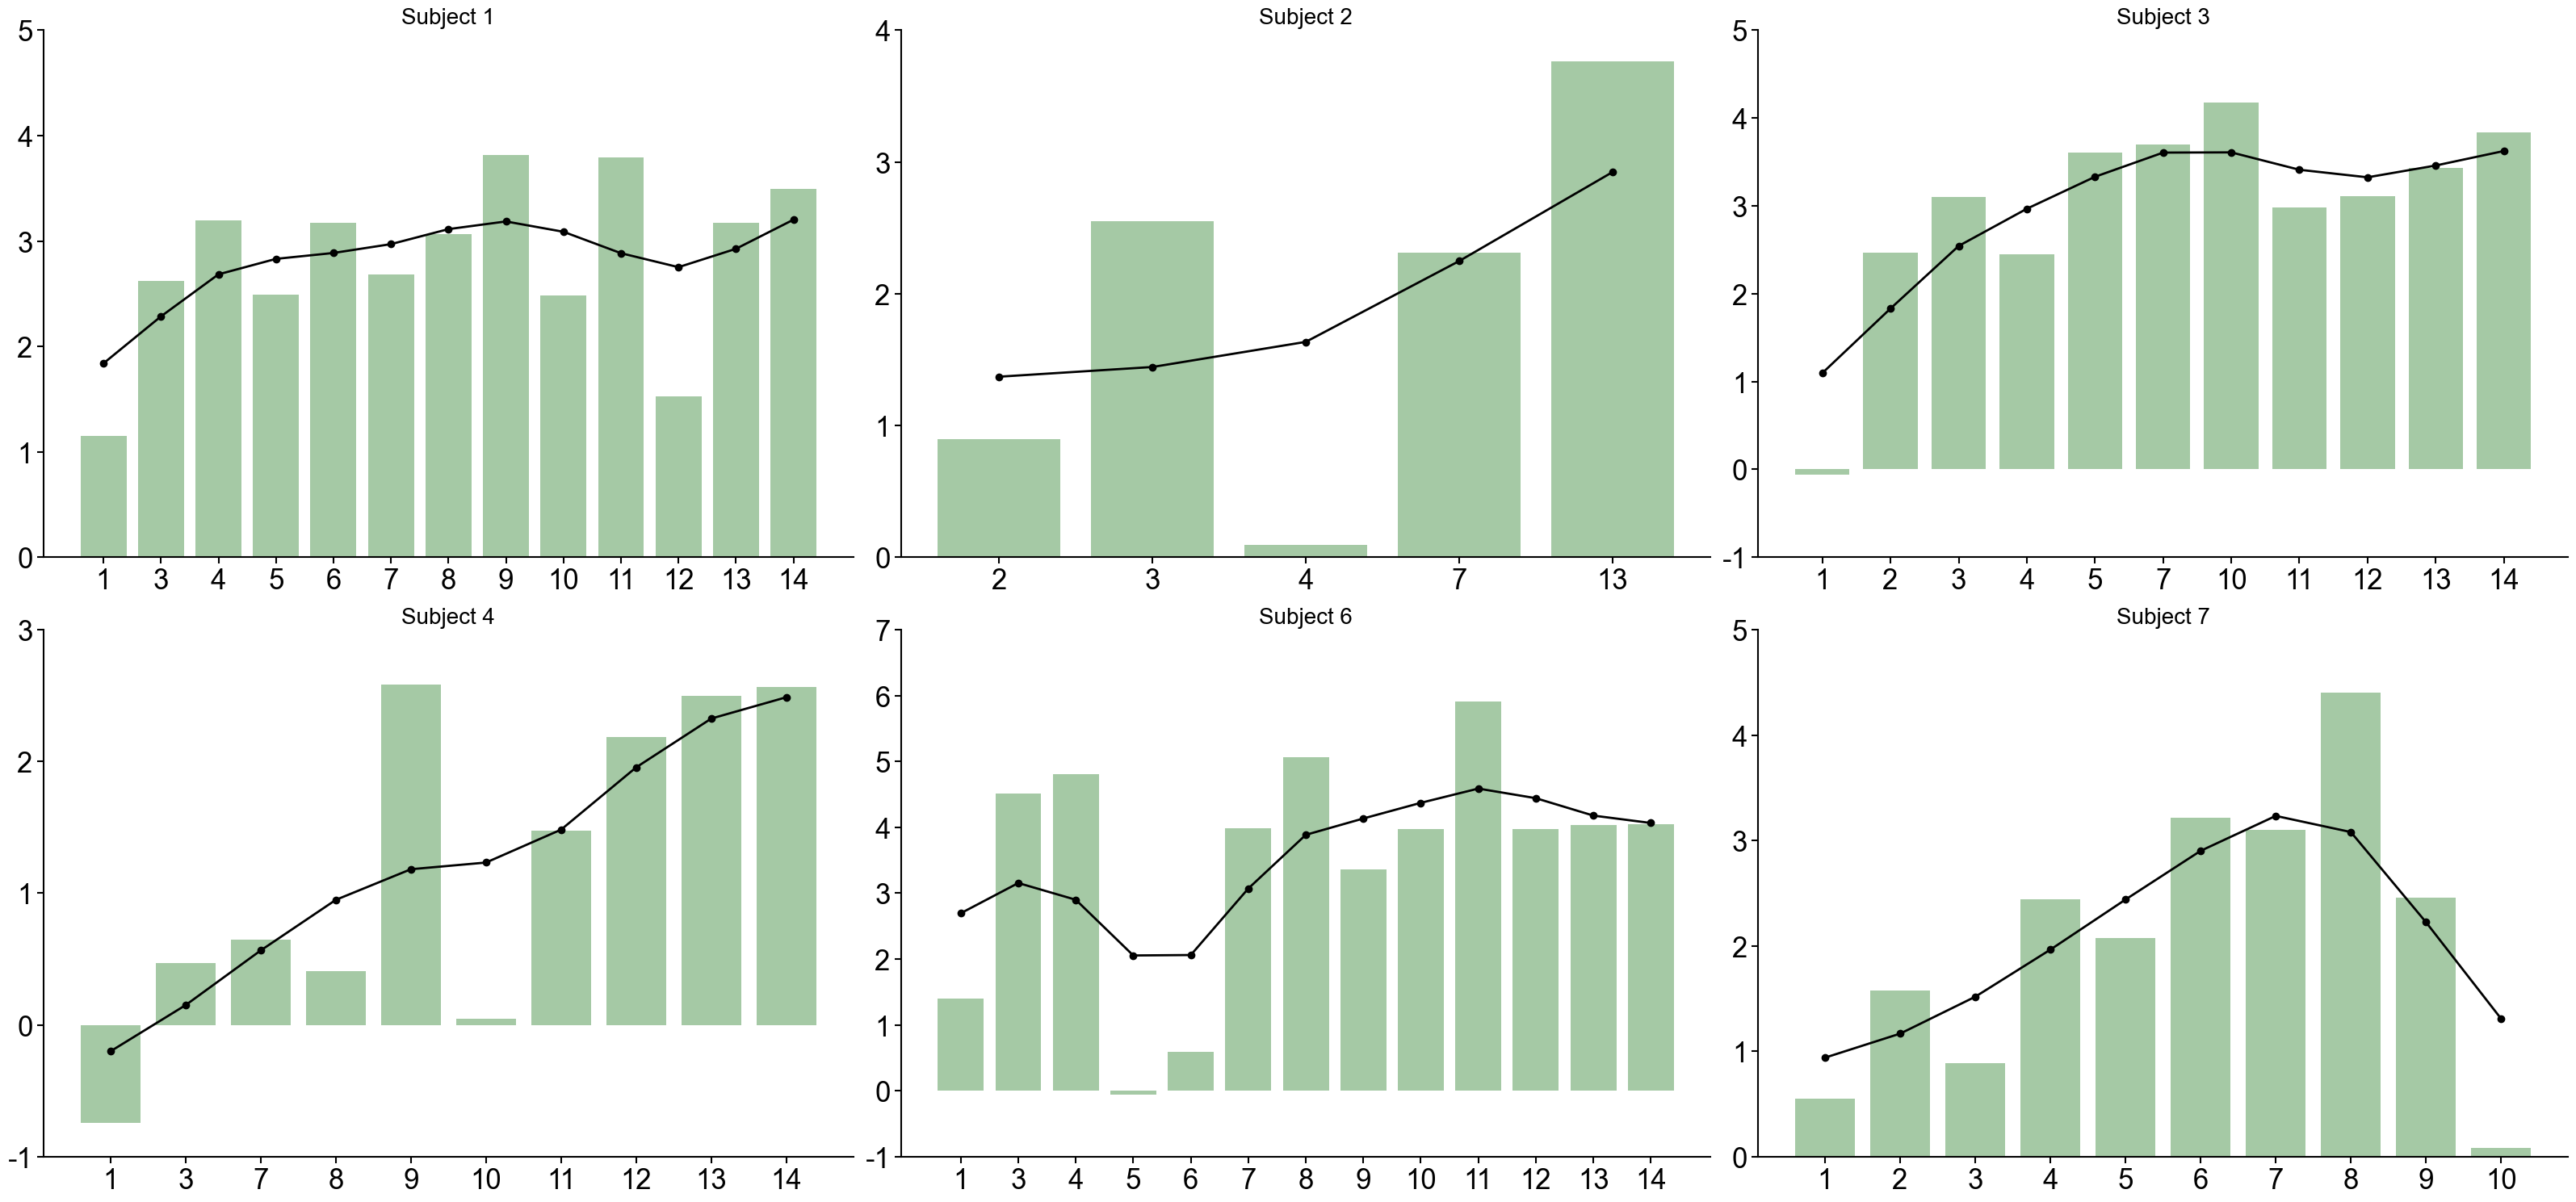

In [77]:
from functions_experimental_data_Bräckleinexp.decorrelation_time import *
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import re
import pickle

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def plot_prolonged_firing_duration(directory_path, fsamp=2048,scatter_save_path=None, trend_save_path=None):
    
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    num_days = len(session_days)
    if num_days <= 20:
        color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
    else:
        color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

    total_dur = []
    colors = []
    day_durations = {day: [] for day in session_days}

    for file_name in sorted_pkl_files:
        file_path = os.path.join(directory_path, file_name)
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_MU = np.array(data['MU'].tolist())
        idx_pair = data['Idx_MU_Pair'].tolist()

        spike_small = np.where(data_MU[idx_pair[0]] == 1)[0]
        spike_large = np.where(data_MU[idx_pair[1]] == 1)[0]

        if len(spike_small) == 0 or len(spike_large) == 0:
            continue

        duration = (spike_large[-1] - spike_small[-1]) / fsamp
        total_dur.append(duration)

        day = extract_day(file_name)
        colors.append(color_map[day])
        day_durations[day].append(duration)

    day_avg_durations = {day: np.mean(durations)for day, durations in day_durations.items() if durations}

    time = np.arange(len(total_dur))
    plt.figure(figsize=(10, 6))
    plt.scatter(time, total_dur, color=colors, alpha=0.8)
    plt.xlabel("File Index")
    plt.ylabel("Prolongated Firing Duration (s)")
    plt.title("Prolongated Firing Duration Across Sessions")

    for day, color in color_map.items():
        plt.scatter([], [], color=color, label=day)

    plt.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    if scatter_save_path:
        plt.savefig(scatter_save_path, dpi=300, bbox_inches='tight')
    plt.show()

    # Step 7: Bar plot with smoothed trend
    sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
    sorted_avg = [day_avg_durations[day] for day in sorted_days]
    smoothed_avg = gaussian_filter1d(sorted_avg, sigma=1.2)

    plt.figure(figsize=(12, 6))
    plt.bar(sorted_days, sorted_avg, color=[color_map[day] for day in sorted_days], alpha=0.6, label="Avg Duration")
    plt.plot(sorted_days, smoothed_avg, marker='o', linestyle='-', color='black', linewidth=2, label="Trend")

    plt.xlabel("Session Day")
    plt.ylabel("Average Prolongated Firing Duration (s)")
    plt.title("Average Prolongated Firing Duration Per Session (with Trend)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    if trend_save_path:
        plt.savefig(trend_save_path, dpi=300, bbox_inches='tight')
    plt.show()

def plot_groupwise_prolonged_firing(session_files_dict, base_data_dir, fsamp=2048,save_path=None):
    """
    Plot average prolongated firing durations with smoothed trend across multiple subjects.

    Parameters:
    - session_files_dict: dict of dicts, e.g. {'S1': {'Day01': [...], 'Day02': [...]}, ...}
    - base_data_dir: str, path to the directory containing subject folders
    - fsamp: int, sampling frequency
    - save_path: str or None, if given, figure is saved there
    """
    fig, axes = plt.subplots(2, 3, figsize=(32, 15))
    axes = axes.flatten()

    for idx, (subject, subject_sessions) in enumerate(session_files_dict.items()):
        directory_path = os.path.join(base_data_dir, subject)
        day_durations = {day: [] for day in subject_sessions.keys()}

        for day, files in subject_sessions.items():
            for file_name in files:
                file_path = os.path.join(directory_path, file_name)
                with open(file_path, 'rb') as f:
                    data = pickle.load(f)

                data_MU = np.array(data['MU'].tolist())
                idx_pair = data['Idx_MU_Pair']

                spikes_small = np.where(data_MU[idx_pair[0]] == 1)[0]
                spikes_large = np.where(data_MU[idx_pair[1]] == 1)[0]

                if len(spikes_small) == 0 or len(spikes_large) == 0:
                    continue

                dur = (spikes_large[-1] - spikes_small[-1]) / fsamp
                day_durations[day].append(dur)

        # Compute averages
        day_avg_durations = {day: np.mean(durs) for day, durs in day_durations.items() if durs}
        sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
        sorted_avg_durations = [day_avg_durations[day] for day in sorted_days]
        smoothed_avg_durations = gaussian_filter1d(sorted_avg_durations, sigma=1.2)

        # Plotting
        ax = axes[idx]
        ax.bar(range(len(sorted_days)), sorted_avg_durations, color='#8FBC8F', alpha=0.8)
        ax.plot(range(len(sorted_days)), smoothed_avg_durations, marker='o',linestyle='-', color='black', linewidth=2)

        ax.set_title(f"Subject {subject[1]}", fontsize=20)
        day_numbers = [int(day[3:]) for day in sorted_days]
        ax.set_xticks(range(len(sorted_days)))
        ax.set_xticklabels(day_numbers, fontsize=25, rotation=0)
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=25)

        y_ticks = ax.get_yticks()
        y_ticks_int = [int(t) for t in y_ticks if np.isclose(t, round(t))]
        ax.set_yticks(y_ticks_int)
        ax.set_yticklabels([str(t) for t in y_ticks_int], fontsize=25)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        for spine in ['left', 'bottom']:
            ax.spines[spine].set_linewidth(1.5)

        ax.set_xlabel("")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()




plot_groupwise_prolonged_firing(session_files_dict={
        'S1': session_files1,
        'S2': session_files2,
        'S3': session_files3,
        'S4': session_files4,
        'S6': session_files6,
        'S7': session_files7
    },
    base_data_dir="/Users/nmt121/Desktop/DATA",
    fsamp=2048,
    # save_path="/Users/nmt121/Desktop/hysteresisdecorrtime.pdf"
)

In [98]:
def plot_single_subject_prolonged_firing(subject_key, session_files_dict, base_data_dir, fsamp=2048, save_path=None):
    import matplotlib.pyplot as plt
    import numpy as np
    import os
    import pickle
    import re
    from scipy.ndimage import gaussian_filter1d

    # Set font
    plt.rcParams['font.family'] = 'Arial'

    session_files = session_files_dict[subject_key]
    directory_path = os.path.join(base_data_dir, subject_key)
    day_durations = {day: [] for day in session_files.keys()}

    # Extract durations
    for day, files in session_files.items():
        for file_name in files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)

            data_MU = np.array(data['MU'].tolist())
            idx_pair = data['Idx_MU_Pair']
            
            if data['MU'].shape[1]/2048>18:
                continue

            spikes_small = np.where(data_MU[idx_pair[0]] == 1)[0]
            spikes_large = np.where(data_MU[idx_pair[1]] == 1)[0]

            if len(spikes_small) == 0 or len(spikes_large) == 0:
                continue

            dur = (spikes_large[-1] - spikes_small[-1]) / fsamp
            day_durations[day].append(dur)

    # Compute average per day
    day_avg_durations = {day: np.mean(durs) for day, durs in day_durations.items() if durs}
    sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))
    x_labels = [int(day[3:]) for day in sorted_days]
    y_values = [day_avg_durations[day] for day in sorted_days]
    x_positions = np.arange(len(y_values))
    smoothed_values = gaussian_filter1d(y_values, sigma=1.5)

    # === Plotting ===
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(x_positions, y_values, capsize=5, color='#8FBC8F', alpha=0.8)
    ax.plot(x_positions, smoothed_values, color='black', marker='o', linestyle='-', linewidth=2)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=30)
    ax.tick_params(axis='both', which='major', width=2, length=6, labelsize=30)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2)
    ax.spines['bottom'].set_linewidth(2)

    plt.tight_layout()
    # if save_path:
    #     plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_single_subject_prolonged_firing(
    subject_key='S7',
    session_files_dict={
        'S1': session_files1,
        'S2': session_files2,
        'S3': session_files3,
        'S4': session_files4,
        'S6': session_files6,
        'S7': session_files7
    },
    base_data_dir="/Users/nmt121/Desktop/DATA",
    fsamp=2048,
    save_path="/Users/nmt121/Desktop/Figures/Decorrelation_times/Decorrelation_time_experimental7.pdf"
)


FileNotFoundError: [Errno 2] No such file or directory: '/Users/nmt121/Desktop/DATA/S7/E3_MB07_Day09High_12.pkl'

In [86]:
16128/2048

7.875

## FIRING RATES

In [3]:
def spikes_to_firing_rate(spike_array, fs, window_duration=0.3):
    
    n_units, T = spike_array.shape
    wlen = int(round(window_duration * fs))
    wlen = max(3, wlen + (wlen % 2 == 0))  # prefer odd length >=3
    h = windows.hann(wlen)
    h /= h.sum()
    fr = np.empty_like(spike_array, dtype=float)
    for i in range(n_units):
        fr[i] = convolve(spike_array[i], h, mode='same') * fs
    return fr

### FR experimental data

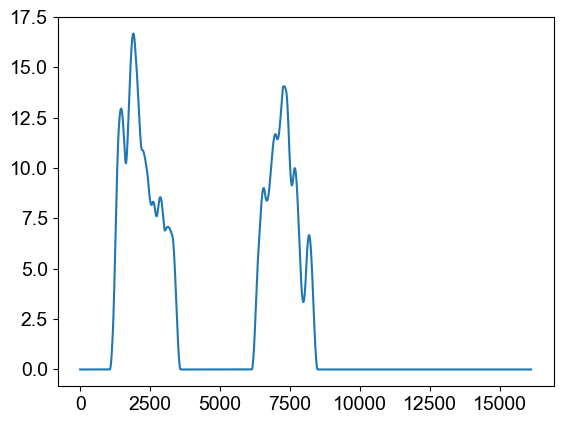

In [76]:

file_path = "/Users/nmt121/Desktop/DATA/S1/E3_MB01_Day14High_28.pkl"



with open(file_path, "rb") as f:
    data = pickle.load(f)

spike_array = data["MU"]  
fs = 2048  
fr_exp = spikes_to_firing_rate(spike_array, fs, window_duration=0.3)
fr_exp.T.shape
plt.plot(fr_exp[0,:])

In [65]:
data["Idx_MU_Pair"]  


array([9, 3], dtype=uint8)

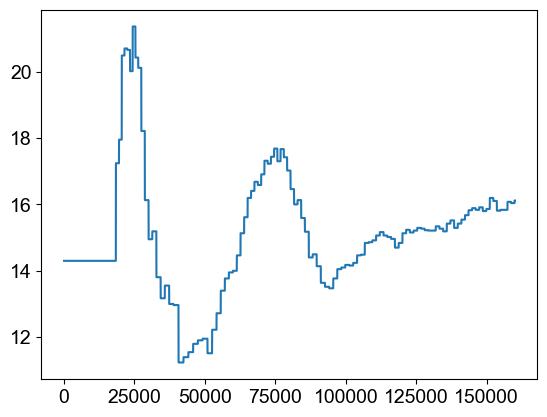

In [80]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/all_rates_full14.jld2" 
with h5py.File(file_path, "r") as f:
    fr_sim = f["rates_full"][:]  

fr_sim.shape
plt.plot(fr_sim[:,3])

In [69]:
# downsample simulation to experimental length
target_len = fr_exp.shape[1]
fr_sim_resampled = resample(fr_sim.T, target_len, axis=1)
print(fr_sim_resampled.shape)  # (181, 43264)

(181, 43264)


In [70]:
n_exp, T = fr_exp.shape
n_sim, _ = fr_sim_resampled.shape

corr_matrix = np.zeros((n_exp, n_sim))
for i in range(n_exp):
    for j in range(n_sim):
        corr_matrix[i, j] = pearsonr(fr_exp[i], fr_sim_resampled[j])[0]



Experimental neuron 0 ↔ Simulated neuron 66 | r = 0.249
Experimental neuron 1 ↔ Simulated neuron 27 | r = 0.697
Experimental neuron 2 ↔ Simulated neuron 55 | r = 0.363
Experimental neuron 3 ↔ Simulated neuron 23 | r = 0.490
Experimental neuron 4 ↔ Simulated neuron 66 | r = 0.341
Experimental neuron 5 ↔ Simulated neuron 27 | r = 0.685
Experimental neuron 6 ↔ Simulated neuron 55 | r = 0.420
Experimental neuron 7 ↔ Simulated neuron 50 | r = 0.682
Experimental neuron 8 ↔ Simulated neuron 68 | r = 0.436
Experimental neuron 9 ↔ Simulated neuron 51 | r = 0.536
Experimental neuron 10 ↔ Simulated neuron 55 | r = 0.271
Experimental neuron 11 ↔ Simulated neuron 66 | r = 0.357
Experimental neuron 12 ↔ Simulated neuron 66 | r = 0.433
Experimental neuron 13 ↔ Simulated neuron 27 | r = 0.335
Experimental neuron 14 ↔ Simulated neuron 55 | r = 0.389


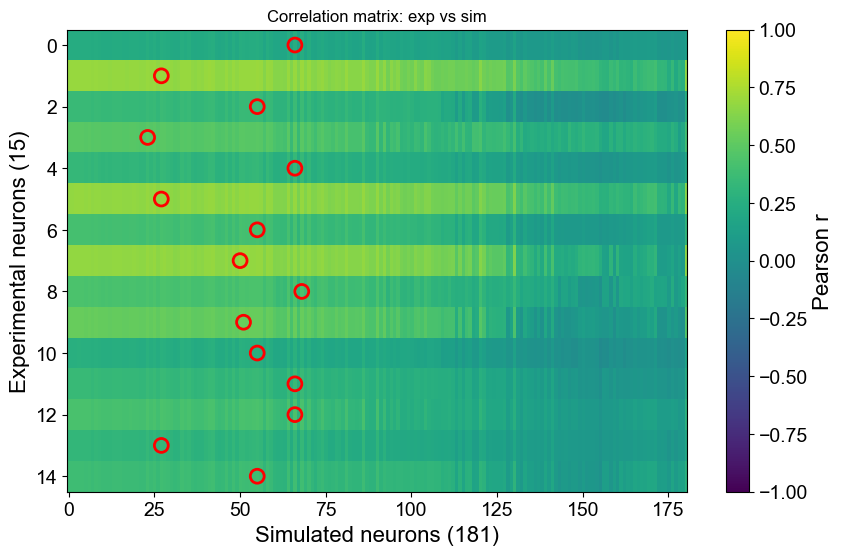

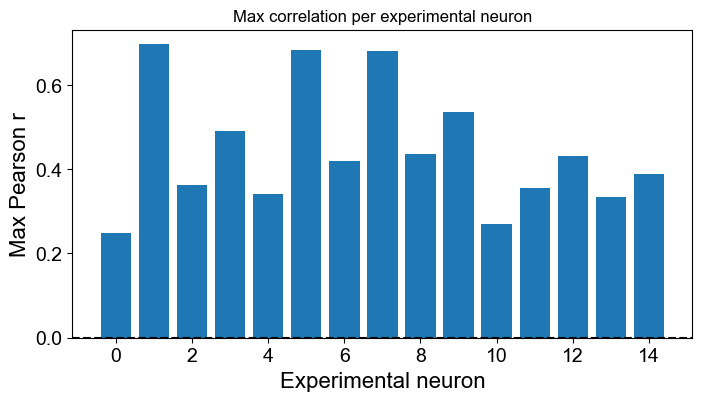

In [71]:
# 1. Compute max per row
max_vals = corr_matrix.max(axis=1)   # length = 15
best_match = corr_matrix.argmax(axis=1)  # index of best simulated neuron per row

# Print matches
for exp_idx, (sim_idx, corr) in enumerate(zip(best_match, max_vals)):
    print(f"Experimental neuron {exp_idx} ↔ Simulated neuron {sim_idx} | r = {corr:.3f}")

# 2. Plot the heatmap + red markers
plt.figure(figsize=(10,6))
im = plt.imshow(corr_matrix, aspect='auto', cmap='viridis', vmin=-1, vmax=1)
# im.savefig("/Users/nmt121/Desktop/corr.pdf", dpi=300, bbox_inches='tight')

plt.colorbar(im, label="Pearson r")
plt.xlabel("Simulated neurons (181)")
plt.ylabel("Experimental neurons (15)")
plt.title("Correlation matrix: exp vs sim")

# add red circle markers on maxima
for exp_idx, sim_idx in enumerate(best_match):
    plt.scatter(sim_idx, exp_idx, s=100, facecolors='none', edgecolors='red', linewidths=2)
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')

plt.show()

# 3. Plot the max values per row as a bar plot
plt.figure(figsize=(8,4))
plt.bar(np.arange(len(max_vals)), max_vals, color="C0")
plt.axhline(0, color='k', linestyle='--')
plt.ylabel("Max Pearson r")
plt.xlabel("Experimental neuron")
plt.title("Max correlation per experimental neuron")
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')
plt.show()